In [1]:
from math import ceil
from glob import glob
import numpy as np
import matplotlib.pyplot as plt
from pyspan.io import read_ta_dat, pack_trace
from pyspan.utils import nm2ev, between
from ipywidgets import interact, interactive, fixed, interact_manual, GridspecLayout, AppLayout, Button
import ipywidgets as widgets
from numpy.polynomial import Polynomial
from scipy.interpolate import InterpolatedUnivariateSpline
from scipy.spatial.distance import cdist, correlation

In [2]:
%matplotlib widget

# Select files

In [ ]:
# use `glob` to select files
fnames = glob("s[3][0-7].dat")#+glob("s[3][0-1].dat")#+ glob("s7[0-7].dat")
# setup an output root file name
out_root = "s"+fnames[0][1:-4]+fnames[-1][1:-4]+'_' #"s"+fnames[0][1:-4]+fnames[7][1:-4]+'s'+fnames[8][1:-4]+fnames[-1][1:-4]+'_' 
print(fnames, out_root)
   
date = '250307_' 
sample = 'LCH_' 
solvent = 'thf_' 
step = '200' 
rel_pol = 'm' 
pump_power = '0.17' 
pump_wl = '350' 

['s30.dat', 's31.dat', 's32.dat', 's33.dat', 's34.dat', 's35.dat', 's36.dat', 's37.dat'] s3037_


In [26]:
# Load all ta_data into a dictionnary. It maps {fn: (t, wl, dod)}
dat = {fn: read_ta_dat(fn) for fn in fnames}

In [ ]:
def cut_wl(entry, wl_lim):
    """ 
    Can be used to cut the wavelength range of the entries in the dat dictionary.
    
    Parameters
    ----------
    entry : tuple
        One entry from the dat dictionary, which is a tuple containing time, wavelength, and data arrays.
    wl_lim : tuple
        A tuple containing the lower and upper wavelength limits (in nm).

    Returns
    -------
    tuple
        A tuple again with shape of the dat dict entry, but with the wl cut. 
    """
    t, wl, z = entry
    m = (wl >= wl_lim[0]) & (wl <= wl_lim[1])
    return t, wl[m], z[m, :]

wl_lim = (400, 700) # I choose a high limit for the upper bound so it is not cut

dat = {fn: cut_wl(dat[fn], wl_lim) for fn in fnames}

In [ ]:
# border for pre t0 subtraction
sub_t = -0.15 

In [34]:
# Check all times are the same
all_t = np.array([d[0] for d in dat.values()])
assert np.allclose(all_t[0], all_t)
t = all_t[0]
# Check all wavelengths are the same
all_wl = np.array([d[1] for d in dat.values()])
assert np.allclose(all_wl[0], all_wl)
wl = all_wl[0]
# Load all the delta A data.
dod = np.array([d[2] for d in dat.values()])

# subtract before time 0
bksub = dod - np.mean(dod.compress(t<sub_t, axis=2), axis=2)[:,:,np.newaxis] 

In [35]:
# The axes of dod are: files, wl, time
dod.shape, (len(fnames), wl.size, t.size)

((8, 358, 351), (8, 358, 351))

# plot the traces

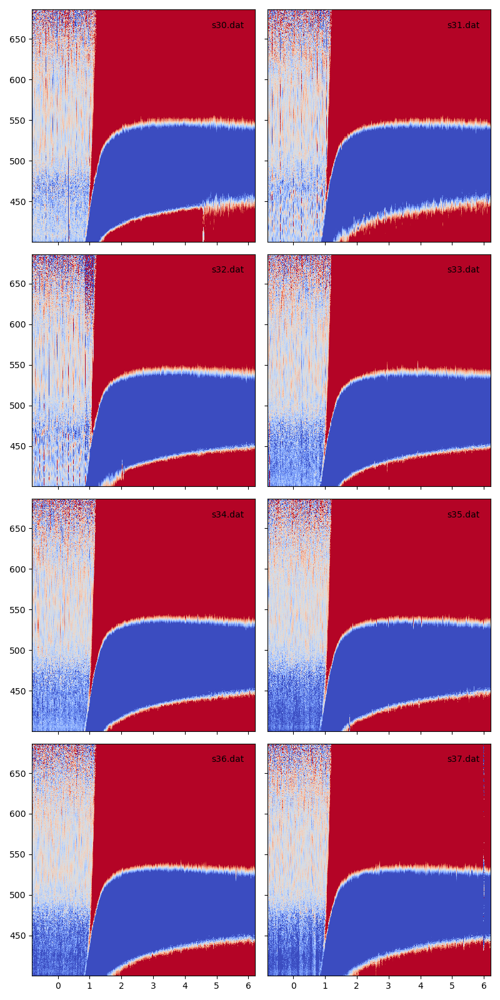

In [ ]:
# Setup two columns.
nrows = ceil(len(fnames)/2)
fig, axes = plt.subplots(nrows=nrows, ncols=2, sharex=True, sharey=True, figsize=(8,nrows*4))

# You can modify the limits of the colormap here
clim = 0.5 

# plot the trace for all filenames
for i, (fn, ax) in enumerate(zip(fnames, axes.flat)):
    plt.sca(ax)
    plt.pcolormesh(t, wl, dod[i,:,:], cmap="coolwarm", vmin=-clim, vmax=clim)
    plt.text(0.95, 0.95, fnames[i], transform=ax.transAxes, va="top", ha="right")
plt.tight_layout()

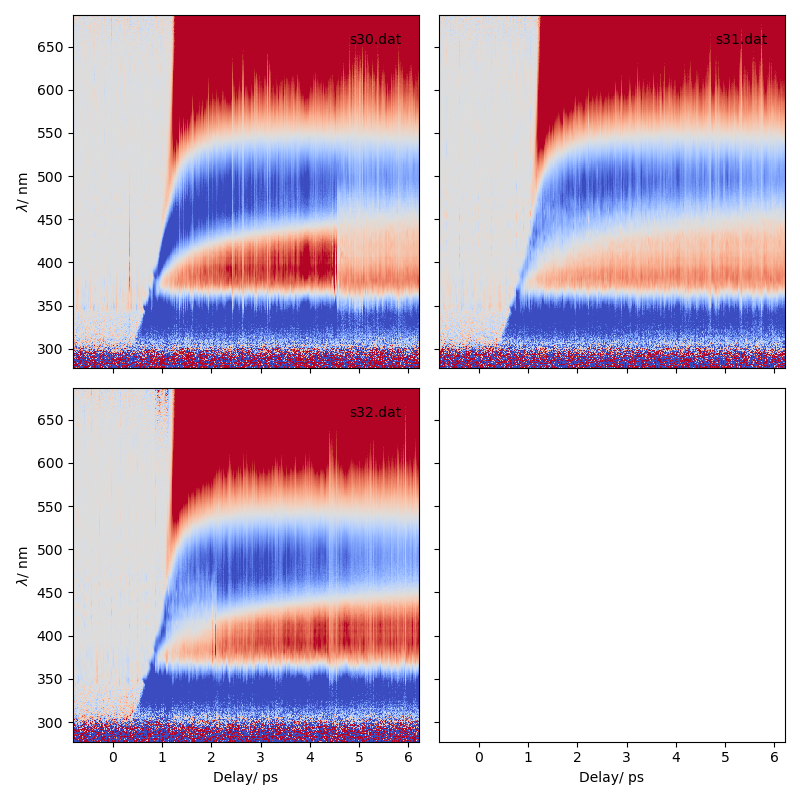

In [ ]:
# Same thing, after subtraction of t0
nrows = ceil(len(fnames)/2)
fig, axes = plt.subplots(nrows=nrows, ncols=2, sharex=True, sharey=True, figsize=(8,nrows*4))

# plot the trace for all filenames
for i, (fn, ax) in enumerate(zip(fnames, axes.flat)):
    plt.sca(ax)
    plt.pcolormesh(t, wl, bksub[i,:,:], cmap="coolwarm", vmin=-clim, vmax=clim)
    plt.text(0.95, 0.95, fnames[i], transform=ax.transAxes, va="top", ha="right")
#axes = np.atleast_2d(axes) 
for ax in axes[:,0]:
    ax.set_ylabel(r"$\lambda$/ nm")
for ax in axes[-1,:]:
    ax.set_xlabel(r"Delay/ ps")
plt.tight_layout()

# Compute RMDS, reject bad pulses and average

In [17]:
# Close graphs to save memory
plt.close("all")

In [ ]:
# If there is too much scatter, we should remove the pump scatter from rmsd calculation
# This is done by setting finite bounds for `pump_lo`, `pump_hi`
pump_lo, pump_hi = -np.inf, -np.inf
sub_temp = bksub.compress(~between(wl, pump_lo, pump_hi), axis=1)

# compute median for all files at a given delay and wavelength
# then, compute rmsd. This was done using "euclidean distance" because I was playing around
medn = np.ma.median(sub_temp, axis=0)
rmsd = np.array([
    cdist(sub_temp[:,:,i], [ medn[:,i]], metric="euclidean",)
    for i in range(dod.shape[-1])])
rmsd = rmsd.squeeze().T  

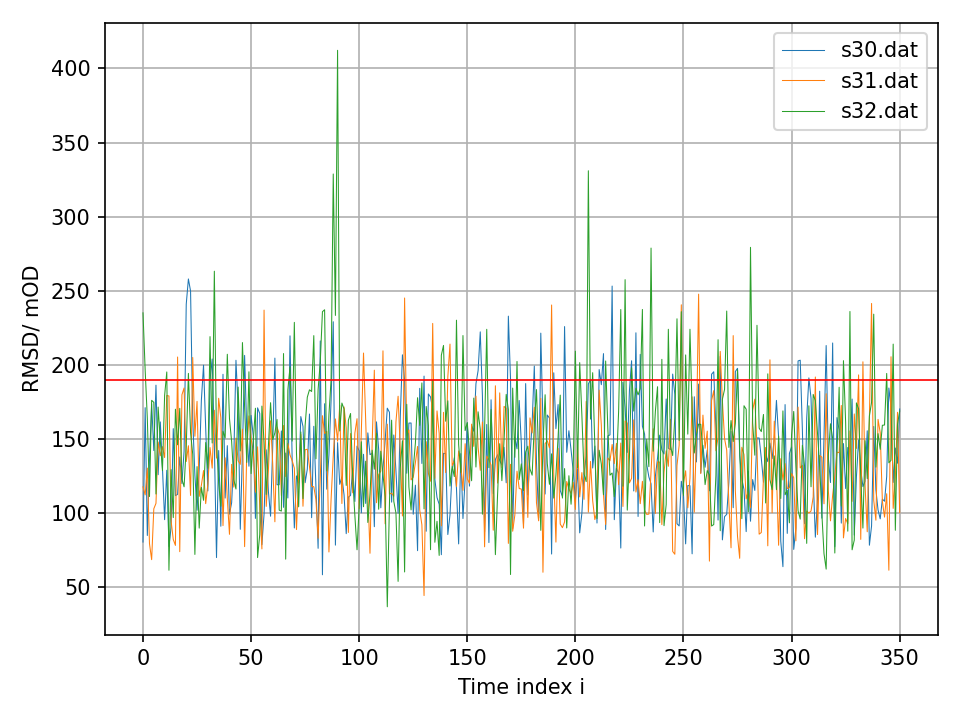

In [ ]:
threshold = 190 
plt.figure(dpi=150)
plt.plot(rmsd.T, "-", lw=0.5, label=fnames)
#plt.ylim(0,50)
plt.xlabel("Time index i")
plt.ylabel("RMSD/ mOD")
plt.legend()
plt.grid()
plt.axhline(threshold, color='r', linewidth=0.8) 
plt.tight_layout()

In [20]:
# set the threshold for rejection, and reject these pulses
# This is implemented using a "masked array" (see `numpy.ma`)
is_bad = rmsd > threshold
dod_masked = np.ma.masked_where(
    np.broadcast_to(is_bad[:,np.newaxis,:], dod.shape),  # use `is_bad`, but ensure it has the correct shape
    np.ma.getdata(dod)  # get the original data from dod
)

interactive(children=(IntSlider(value=0, description='i', max=511), IntRangeSlider(value=(0, 1), description='…

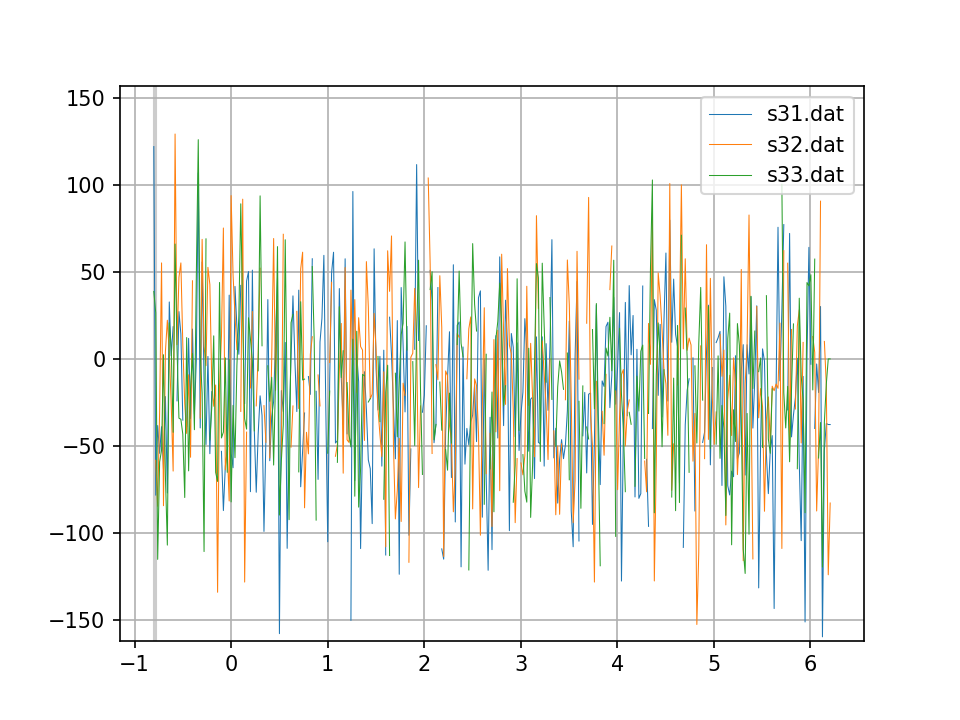

In [69]:

# Plot the kinetic transients at specific wavelength.
# the `wl` cursor controls which wl is displayed.
# The `bnds` cursor are just there to help indentify bounds for manual rejection

fig = plt.figure(dpi=150)

i = 0
ymin = np.min(dod_masked)
ymax = np.max(dod_masked)
curves = plt.plot(t, dod_masked[:,i,:].T, lw=0.5, label=fnames)
span = plt.axvspan(0, 1, color="0.8")
plt.ylim(ymin, ymax)
plt.grid()
plt.legend()

idx = widgets.IntSlider(i, 0, len(wl)-1)
idx.desc_fmt = "wl = {:.02f}"


@interact(i=idx, bnds = widgets.IntRangeSlider(value=[0,1], min=0, max=len(t)-1))
def _update(i, bnds):
    for j, c in enumerate(curves):
        c.set_ydata(dod_masked[j,i,:])
    idx.description = idx.desc_fmt.format(wl[i])
    lo, hi = bnds
    span.xy[[0,1,4],0] = t[lo]
    span.xy[[2,3],0] = t[hi]


In [ ]:
# You can reject specific pulses manually like in the lines below.
# We assign the value `np.ma.masked` to slices in dod_masked. This masks the value/
# The slice is as follows: [file_index, all the spectrum, a range indices]
# file_index is the position of the file in `fnames`,
# : means do it for the whole spectrum
# range(a, b) reject indices a to b, excluding the endpoint

#dod_masked[2,:,range(299,305)] = np.ma.masked  # Reject spectra 285-303 from fnames[1]
# dod_masked[1,:,range(320,331)] = np.ma.masked  # Reject spectra 320-331 from fnames[1]
# dod_masked[4,:,range(65,67)] = np.ma.masked  # Reject spectra 65-67 from fnames[4]
# dod_masked[4,:,[148,]] = np.ma.masked  # Reject spectrum 148 from fnames[4]

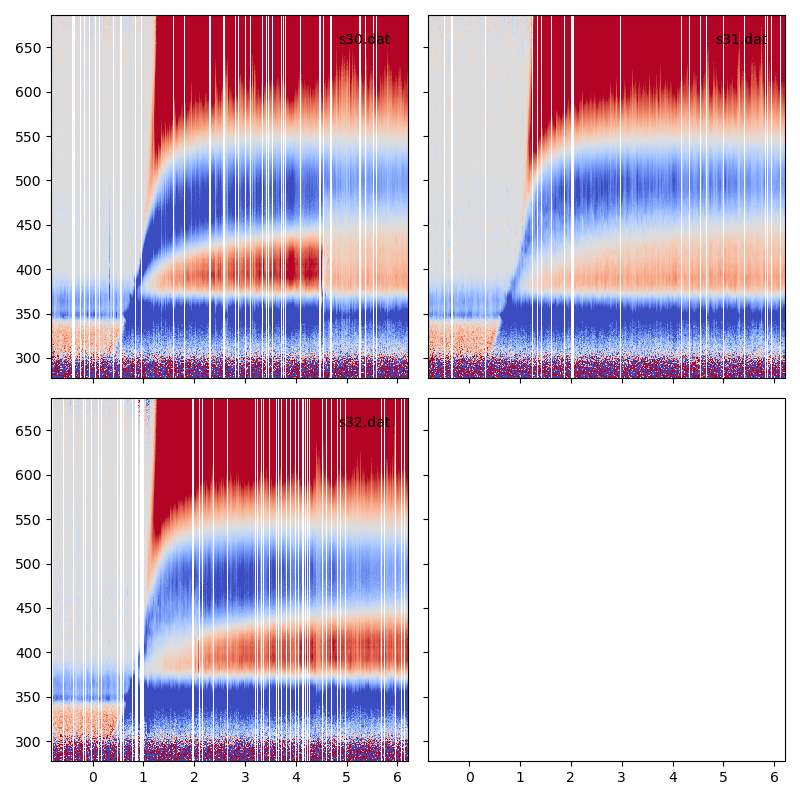

In [21]:
# Inspect the traces after rejection
nrows = ceil(len(fnames)/2)
fig, axes = plt.subplots(nrows=nrows, ncols=2, sharex=True, sharey=True, figsize=(8,nrows*4))

# plot the trace for all filenames
for i, (fn, ax) in enumerate(zip(fnames, axes.flat)):
    plt.sca(ax)
    plt.pcolormesh(t, wl, dod_masked[i,:,:], cmap="coolwarm", vmin=-clim, vmax=clim)
    plt.text(0.95, 0.95, fnames[i], transform=ax.transAxes, va="top", ha="right")
plt.tight_layout()

In [22]:
# Perform the average, rejecting the masked values
avg = np.ma.mean(dod_masked, axis=0)
negspec = avg.compress(t<sub_t, axis=1).mean(axis=1) # negative delay spectrum
avg_sub = avg-negspec[:,np.newaxis]  # scatter removal (remove negative delay spectrum)

## Plot the average

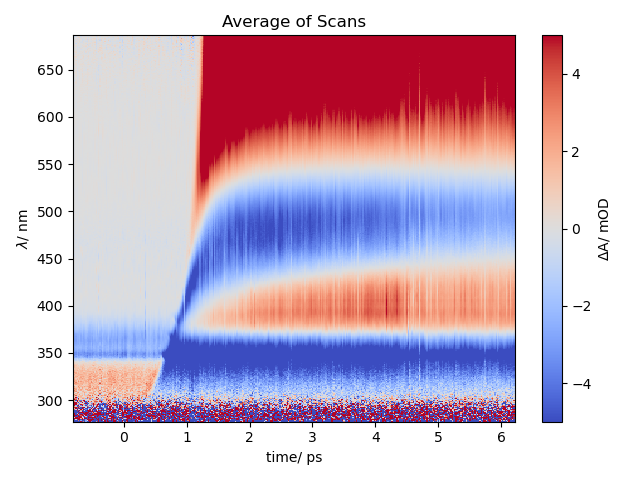

In [ ]:
# with pre time zero spectra
plt.figure()
#lim = np.max(np.abs(avg))
plt.pcolormesh(t, wl, avg, cmap="coolwarm", vmin=-clim, vmax=clim)
plt.xlabel("time/ ps")
plt.ylabel(r"$\lambda$/ nm")
plt.title('Average of Scans')
plt.colorbar(label=r"$\Delta$A/ mOD")
plt.tight_layout()

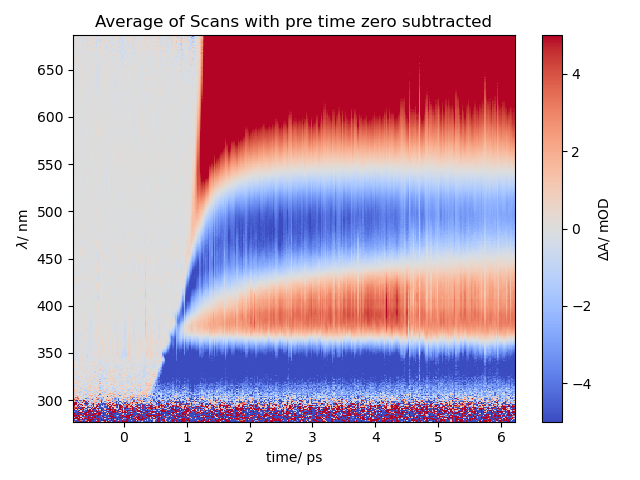

In [ ]:
# without pre time zero spectra
plt.figure()
#lim = np.max(np.abs(avg_sub))*0.8 
plt.pcolormesh(t, wl, avg_sub, cmap="coolwarm", vmin=-clim, vmax=clim)
plt.xlabel("time/ ps")
plt.ylabel(r"$\lambda$/ nm")
plt.title('Average of Scans with pre time zero subtracted')
plt.colorbar(label=r"$\Delta$A/ mOD")
plt.tight_layout()

In [ ]:
# save average
#np.savetxt(date+sample+solvent+step+rel_pol+out_root+pump_power+'mW_'+pump_wl+"nm_only_avg.dat", pack_trace(t, wl, avg), fmt="%0.6e")
#np.savetxt(date+sample+solvent+step+rel_pol+out_root+pump_power+'mW_'+pump_wl+"nm_no_t0corr.dat", pack_trace(t, wl, avg_sub), fmt="%0.6e")
#np.savetxt(date+solvent+step+rel_pol+out_root+pump_power+'mW_'+pump_wl+"nm_solvent_signal.dat", pack_trace(t, wl, avg_sub), fmt="%0.6e")

In [ ]:
# OK this works. Add buttons to fit and shift trace. Remember how to evaluate errors.
# Prettify the plots(axes labels...). Use a fixed gridspec, not constrainted or whatever.
# Make a function to shift the trace.
# Pack the tools for t0 curve determination process into a class.
# Make display with 2 panels at the bottom: original+pol, and shifted?

# Determine t0 correction curve by clicking.

In [ ]:
# This is a big one...

# Here are the real parameters.
# dn = 8 means we determine t0 every 8 wavelength values
# t_min and t_max control the delays which are shown on the plot
# z_lim is the colorbar limits on the reference colormap
dn = 8
t_min = -0.5
t_max = 1.5
z_lim = 2#15

# this variable stores our time points
points = {}  # j: (wl, t0)
# it actually maps "pixel index j" to both wavelength and t0

# start setting up the graph elements
with plt.ioff():
    fig = plt.figure(dpi=150, constrained_layout=True, figsize=(5,3))
gs = plt.GridSpec(nrows=2, ncols=2, width_ratios=[1,2], height_ratios=[1,1], figure=fig)

kin_ax = fig.add_subplot(gs[:,1])
ctr_ax = fig.add_subplot(gs[1,0])

# kin_ax is for the kinetic transients (main plot)
plt.sca(kin_ax)
i = 0
ymin = np.min(avg_sub)
ymax = np.max(avg_sub)
# curves of all kinetic transients
curves = plt.plot(t, avg_sub[i,:], lw=0.5)
# t0 indicator line
t0_indicator = plt.axvline(np.nan, color="r", lw=0.5, ls="--")
plt.ylim(ymin, ymax)
plt.xlim(t_min, t_max)
plt.grid(True, lw=0.5, color="0.6")

# kin_ax is for the reference colormapped plot
plt.sca(ctr_ax)
plt.pcolormesh(t, wl, avg_sub, cmap="coolwarm", vmin=-z_lim, vmax=z_lim)
# t0 points
t0_line = plt.plot([], [], "ro", ms=2, mec="k", mew=0.8)
# current wl cursor
wl_indicator = plt.axhline(wl[i], color="k", lw=0.5, ls="--")
plt.xlim(t_min, t_max)

# Setup control elements
# A message box to communicate with the user
log = widgets.Label(value="The $m$ in $E=mc^2$:")

# Buttons
next_btn = widgets.Button(description="next", icon="caret-right")
prev_btn = widgets.Button(description="prev", icon="caret-left")
del_btn = widgets.Button(description="Delete", icon="trash")
ascl_btn = widgets.Button(description="autoscale", icon="arrows-alt-v")

# Callbacks
# rescale the kinetic transients
def autoscale(*args):
    dat = np.array([c.get_ydata() for c in curves])
    lo = np.min(dat)
    hi = np.max(dat)
    mrg = (hi-lo)*0.02
    kin_ax.set_ylim(lo-mrg, hi+mrg)

# Redraw the things
def update_plot():
    global i
    curves[0].set_ydata(avg_sub[i,:])
    wl_indicator.set_ydata([wl[i], wl[i]])
    if len(points) > 0:
        wl_, t0_ = np.array(list(points.values())).T
        t0_line[0].set_xdata(t0_)
        t0_line[0].set_ydata(wl_)
    _, t0_ = points.get(i, (np.nan, np.nan))
    t0_indicator.set_xdata([t0_, t0_])
    idx.description = idx.desc_fmt.format(wl[i])
    autoscale()
    log.value = f"i: {i} "

# go to next wl
def go_next(*btn):
    global i
    i = min(i+dn, avg_sub.shape[0]-1)
    update_plot()

# go to previous wl
def go_prev(*btn):
    global i
    i = max(i-dn, 0)
    update_plot()
    
# remove current point from the record
def del_current(*args):
    global i
    try:
        del points[i]
    except KeyError:
        pass
    update_plot()

# Handle click on the kinetic transient.
def on_click(event):
    if event.inaxes == kin_ax and not fig.canvas.toolbar._current_action:
        points[i] = (wl[i], event.xdata)
        go_next(None)
        
# Handle keypresses for left/right keys
def on_keypress(event):
    log.value = f"you pressed {event.key}, {event.xdata}, {event.ydata}"
    if event.key == "left":
        go_prev()
    elif event.key == "right":
        go_next()
    
# handle press on autoscale button
def on_ascale(btn):
    autoscale()

# connect the buttons to the functions
ascl_btn.on_click(on_ascale)
prev_btn.on_click(go_prev)
next_btn.on_click(go_next)
del_btn.on_click(del_current)

# connect the click and keypresses
cid = fig.canvas.mpl_connect('button_press_event', on_click)
fig.canvas.mpl_connect('key_press_event', on_keypress)

# setup a layout for these things, final update and display
layt_btn = widgets.HBox([prev_btn, next_btn, del_btn, ascl_btn])
layout_vert = widgets.VBox([layt_btn, fig.canvas, log])
update_plot()
layout_vert

In [ ]:
# collect the t0 curve
t0_curve = np.vstack(list(points.values()))
# fit a 2nd order polynomial in fequency domain
pol = Polynomial.fit(nm2ev(t0_curve[:,0]), t0_curve[:,1], 2).convert()
# store the correction curve in wl domain
t0_corr = np.vstack([wl, pol(nm2ev(wl))]).T
# plot it above
ctr_ax.plot(pol(nm2ev(wl)), wl, lw=0.8, color="r")

In [ ]:
# save all our correction function
np.savez(date+out_root+solvent+"t0corr.npz", t0_meas = t0_curve, t0_corr = t0_corr, pol_coeff = pol.coef)

# Perform correction

In [25]:
# If you already have a t0_correction curve from another file, load it as follows:
t0_corr = np.load("250307_s1213_thf_t0corr.npz")["t0_corr"]

In [26]:
# Perform correction.
# Define a function to do the shift
def shift_kin(t, y, t0):
    return np.interp(t+t0, t, y, left=np.nan, right=np.nan)

# Initialize an empty array 
shifted = np.zeros_like(avg_sub, subok=False)
# Perform the shift for every wavelength
for i in range(avg_sub.shape[0]):
    shifted[i,:] = shift_kin(t, avg_sub[i,:], t0_corr[i,1])
# clip the edges which include missing data
has_invalid = ~np.any(np.isnan(shifted), axis=0)
# results is in t_c (clipped time axis) and `shifted`
t_c = t.compress(has_invalid)
shifted = shifted.compress(has_invalid, axis=1)

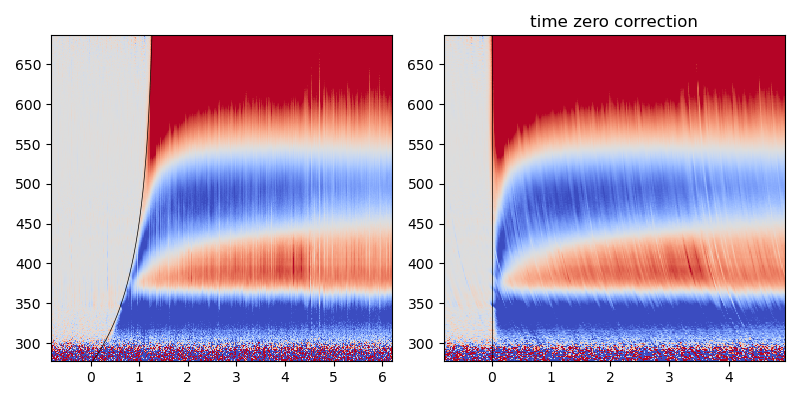

In [ ]:
fig, axes = plt.subplots(ncols=2, figsize=(8,4))
plt.sca(axes[0])
#vmin, vmax = -1, 1
plt.pcolormesh(t, wl, avg_sub, vmin=-clim, vmax=clim, cmap="coolwarm")
_, t0 = t0_corr.T
plt.plot(t0, wl, color="k", lw=0.5)
plt.sca(axes[1])
plt.pcolormesh(t_c, wl, shifted, vmin=-clim, vmax=clim, cmap="coolwarm")
plt.axvline(0, color="k", lw=0.5) 
plt.title('time zero correction') 
plt.tight_layout()

# Processing for single scan 

In [ ]:
# substraction of pre time zero and time correction only for one scan 

scan1 = bksub[0]

t0_corr = np.load("250307_s1213_thf_t0corr.npz")["t0_corr"]

# Perform correction.
# Define a function to do the shift
def shift_kin(t, y, t0):
    return np.interp(t+t0, t, y, left=np.nan, right=np.nan)

# Initialize an empty array 
shifted = np.zeros_like(scan1, subok=False)
# Perform the shift for every wavelength
for i in range(scan1.shape[0]):
    shifted[i,:] = shift_kin(t, scan1[i,:], t0_corr[i,1])
# clip the edges which include missing data
has_invalid = ~np.any(np.isnan(shifted), axis=0)
# results is in t_c (clipped time axis) and `shifted`
t_c = t.compress(has_invalid)
shifted = shifted.compress(has_invalid, axis=1)

np.savetxt(date+sample+solvent+step+rel_pol+'_scan1_'+pump_power+'mW_'+pump_wl+"nm.dat", pack_trace(t_c, wl, shifted), fmt="%0.6e")

(351,)
(512,)
(1, 512, 351)


# Save the output

In [ ]:
# save negative delay spectrum of first and last scan 

print(t.shape)
print(wl.shape)
print(dod.shape)

q=0
print(t[q])
plt.figure()
plt.plot(wl,dod[0][:,q])
plt.plot(wl,dod[-1][:,q])
plt.ylim(-10,15)
plt.grid()
plt.show()

np.savetxt(f"{date}T{t[0]:.1f}ps_scan1_scan8.dat", np.column_stack((wl, dod[0][:,0], dod[1][:,0])), delimiter="\t", header="Wavelength\scan1\scan8", fmt="%.6e")

In [28]:
np.savetxt(date+sample+solvent+step+rel_pol+out_root+pump_power+'mW_'+pump_wl+"nm.dat", pack_trace(t_c, wl, shifted), fmt="%0.6e")
#np.savetxt(date+out_root+"_negdelay.dat", np.vstack([wl, negspec]).T)

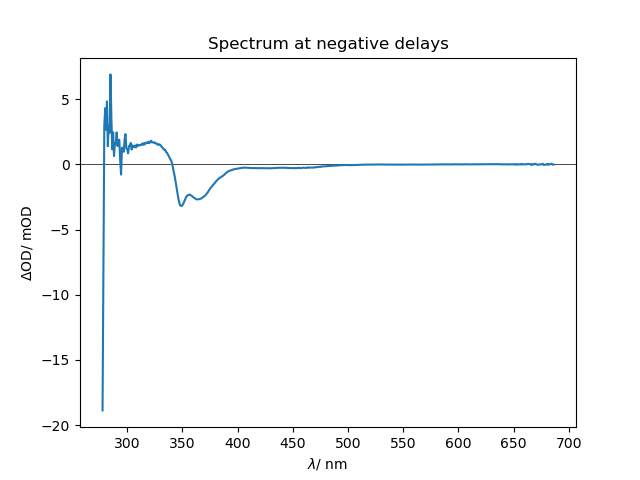

In [49]:
plt.figure()
plt.axhline(0, color="k", lw=0.5)
plt.plot(wl, negspec)
plt.xlabel(r"$\lambda$/ nm")
plt.ylabel(r"$\Delta$OD/ mOD")
plt.title('Spectrum at negative delays')
plt.show()

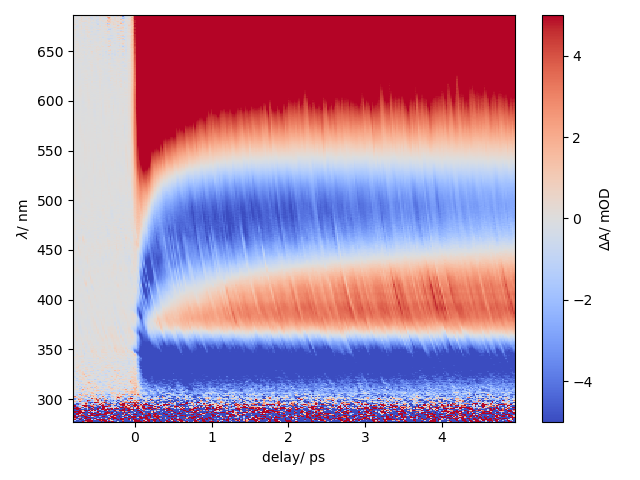

In [80]:
plt.figure()
lim = np.max(np.abs(shifted))*0.8
plt.pcolormesh(t_c, wl, shifted, cmap="coolwarm", vmin=-5, vmax=5)
plt.colorbar(label=r"$\Delta$A/ mOD")
plt.xlabel("delay/ ps")
plt.ylabel(r"$\lambda$/ nm")
plt.tight_layout()
plt.savefig(out_root+".png", dpi=300)